# DoodlioNet — Custom Sketch Classifier Training Pipeline (Google Colab)

This notebook prepares the custom 50-category dataset, trains **DoodlioNet** from scratch with randomly initialized weights, evaluates the model on a held-out test set, and exports the production **ONNX model** with full metadata.

### Workflow:
1. **Colab GPU & Environment Verification**
2. **(Optional) Google Drive Mount** for persistent checkpointing and recovery
3. **Dataset Download & Verification**: 50 curated categories from Google Quick, Draw!
4. **Stratified Split (80% Train / 10% Val / 10% Test)** with zero data leakage
5. **DoodlioNet Architecture**: Custom Residual CNN with Kaiming initialization
6. **Training Loop**: AdamW, Cosine Annealing, Label Smoothing, Early Stopping & Checkpointing
7. **Test Set Evaluation**: Top-1/Top-3 Accuracy, Per-Category Precision/Recall, Confusion Matrix
8. **ONNX Export & Packaging**: `doodlio_artifacts.zip` ready for download into the local `models/` directory


## 1. Check GPU & Hardware Environment


In [12]:
!nvidia-smi
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"Device Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")



Sun Oct 18 09:50:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P0             30W /   70W |    1313MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Mount Google Drive (Optional for Checkpoint Recovery)


In [13]:
import os

MOUNT_DRIVE = True  # Set to True to save checkpoints to Google Drive

if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = '/content/drive/MyDrive/doodlio_checkpoints'
else:
    CHECKPOINT_DIR = '/content/checkpoints'

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs('/content/data/raw', exist_ok=True)
os.makedirs('/content/artifacts', exist_ok=True)
print(f"Checkpoints will be saved to: {CHECKPOINT_DIR}")



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints will be saved to: /content/drive/MyDrive/doodlio_checkpoints


## 3. Install Required Packages


In [14]:
!pip install -q onnx onnxruntime scikit-learn seaborn matplotlib tqdm requests


## 4. Define Curated 50 Categories & Download Dataset


In [15]:
import urllib.parse
import urllib.request
import os
import numpy as np
from tqdm import tqdm

CATEGORIES = [
    {"id": 0, "name": "airplane", "quickdraw_name": "airplane", "display_name": "Airplane", "emoji": "✈️"},
    {"id": 1, "name": "apple", "quickdraw_name": "apple", "display_name": "Apple", "emoji": "🍎"},
    {"id": 2, "name": "banana", "quickdraw_name": "banana", "display_name": "Banana", "emoji": "🍌"},
    {"id": 3, "name": "bicycle", "quickdraw_name": "bicycle", "display_name": "Bicycle", "emoji": "🚲"},
    {"id": 4, "name": "bird", "quickdraw_name": "bird", "display_name": "Bird", "emoji": "🐦"},
    {"id": 5, "name": "bridge", "quickdraw_name": "bridge", "display_name": "Bridge", "emoji": "🌉"},
    {"id": 6, "name": "bus", "quickdraw_name": "bus", "display_name": "Bus", "emoji": "🚌"},
    {"id": 7, "name": "butterfly", "quickdraw_name": "butterfly", "display_name": "Butterfly", "emoji": "🦋"},
    {"id": 8, "name": "camera", "quickdraw_name": "camera", "display_name": "Camera", "emoji": "📷"},
    {"id": 9, "name": "car", "quickdraw_name": "car", "display_name": "Car", "emoji": "🚗"},
    {"id": 10, "name": "castle", "quickdraw_name": "castle", "display_name": "Castle", "emoji": "🏰"},
    {"id": 11, "name": "cat", "quickdraw_name": "cat", "display_name": "Cat", "emoji": "🐱"},
    {"id": 12, "name": "church", "quickdraw_name": "church", "display_name": "Church", "emoji": "⛪"},
    {"id": 13, "name": "clock", "quickdraw_name": "clock", "display_name": "Clock", "emoji": "⏰"},
    {"id": 14, "name": "cloud", "quickdraw_name": "cloud", "display_name": "Cloud", "emoji": "☁️"},
    {"id": 15, "name": "coffee_cup", "quickdraw_name": "coffee cup", "display_name": "Coffee Cup", "emoji": "☕"},
    {"id": 16, "name": "cookie", "quickdraw_name": "cookie", "display_name": "Cookie", "emoji": "🍪"},
    {"id": 17, "name": "cup", "quickdraw_name": "cup", "display_name": "Cup", "emoji": "🥤"},
    {"id": 18, "name": "dog", "quickdraw_name": "dog", "display_name": "Dog", "emoji": "🐶"},
    {"id": 19, "name": "donut", "quickdraw_name": "donut", "display_name": "Donut", "emoji": "🍩"},
    {"id": 20, "name": "drums", "quickdraw_name": "drums", "display_name": "Drums", "emoji": "🥁"},
    {"id": 21, "name": "duck", "quickdraw_name": "duck", "display_name": "Duck", "emoji": "🦆"},
    {"id": 22, "name": "elephant", "quickdraw_name": "elephant", "display_name": "Elephant", "emoji": "🐘"},
    {"id": 23, "name": "envelope", "quickdraw_name": "envelope", "display_name": "Envelope", "emoji": "✉️"},
    {"id": 24, "name": "fish", "quickdraw_name": "fish", "display_name": "Fish", "emoji": "🐟"},
    {"id": 25, "name": "flower", "quickdraw_name": "flower", "display_name": "Flower", "emoji": "🌸"},
    {"id": 26, "name": "frog", "quickdraw_name": "frog", "display_name": "Frog", "emoji": "🐸"},
    {"id": 27, "name": "guitar", "quickdraw_name": "guitar", "display_name": "Guitar", "emoji": "🎸"},
    {"id": 28, "name": "headphones", "quickdraw_name": "headphones", "display_name": "Headphones", "emoji": "🎧"},
    {"id": 29, "name": "house", "quickdraw_name": "house", "display_name": "House", "emoji": "🏠"},
    {"id": 30, "name": "houseplant", "quickdraw_name": "house plant", "display_name": "Houseplant", "emoji": "🪴"},
    {"id": 31, "name": "ice_cream", "quickdraw_name": "ice cream", "display_name": "Ice Cream", "emoji": "🍦"},
    {"id": 32, "name": "leaf", "quickdraw_name": "leaf", "display_name": "Leaf", "emoji": "🍃"},
    {"id": 33, "name": "lightning", "quickdraw_name": "lightning", "display_name": "Lightning", "emoji": "⚡"},
    {"id": 34, "name": "moon", "quickdraw_name": "moon", "display_name": "Moon", "emoji": "🌙"},
    {"id": 35, "name": "mug", "quickdraw_name": "mug", "display_name": "Mug", "emoji": "🍺"},
    {"id": 36, "name": "mushroom", "quickdraw_name": "mushroom", "display_name": "Mushroom", "emoji": "🍄"},
    {"id": 37, "name": "palm_tree", "quickdraw_name": "palm tree", "display_name": "Palm Tree", "emoji": "🌴"},
    {"id": 38, "name": "piano", "quickdraw_name": "piano", "display_name": "Piano", "emoji": "🎹"},
    {"id": 39, "name": "pizza", "quickdraw_name": "pizza", "display_name": "Pizza", "emoji": "🍕"},
    {"id": 40, "name": "rabbit", "quickdraw_name": "rabbit", "display_name": "Rabbit", "emoji": "🐰"},
    {"id": 41, "name": "sailboat", "quickdraw_name": "sailboat", "display_name": "Sailboat", "emoji": "⛵"},
    {"id": 42, "name": "scissors", "quickdraw_name": "scissors", "display_name": "Scissors", "emoji": "✂️"},
    {"id": 43, "name": "speedboat", "quickdraw_name": "speedboat", "display_name": "Speedboat", "emoji": "🚤"},
    {"id": 44, "name": "star", "quickdraw_name": "star", "display_name": "Star", "emoji": "⭐"},
    {"id": 45, "name": "sun", "quickdraw_name": "sun", "display_name": "Sun", "emoji": "☀️"},
    {"id": 46, "name": "traffic_light", "quickdraw_name": "traffic light", "display_name": "Traffic Light", "emoji": "🚦"},
    {"id": 47, "name": "tree", "quickdraw_name": "tree", "display_name": "Tree", "emoji": "🌳"},
    {"id": 48, "name": "umbrella", "quickdraw_name": "umbrella", "display_name": "Umbrella", "emoji": "☂️"},
    {"id": 49, "name": "wine_glass", "quickdraw_name": "wine glass", "display_name": "Wine Glass", "emoji": "🍷"}
]

BASE_URL = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"
SAMPLES_PER_CATEGORY = 10000  # 10k per class = 500k total samples

print(f"Downloading {len(CATEGORIES)} categories from Google QuickDraw...")
for cat in tqdm(CATEGORIES, desc="Categories"):
    fname = cat["name"] + ".npy"
    local_path = os.path.join("/content/data/raw", fname)
    if not os.path.exists(local_path):
        encoded = urllib.parse.quote(cat["quickdraw_name"])
        url = f"{BASE_URL}{encoded}.npy"
        # Download first 10,000 samples using mmap-friendly chunk
        urllib.request.urlretrieve(url, local_path)

print("All category files ready!")



Categories: 100%|██████████| 50/50 [00:00<00:00, 115481.94it/s]

All category files ready!


## 5. Stratified Dataset Split (Zero Data Leakage)


In [16]:
import numpy as np

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

TRAIN_PER_CLASS = 8000
VAL_PER_CLASS = 1000
TEST_PER_CLASS = 1000

train_images, train_labels = [], []
val_images, val_labels = [], []
test_images, test_labels = [], []

print("Partitioning dataset into 80% train, 10% val, 10% test...")
for cat in CATEGORIES:
    cat_id = cat["id"]
    local_path = os.path.join("/content/data/raw", cat["name"] + ".npy")
    data = np.load(local_path, mmap_mode="r")

    # Take first 10,000 samples and shuffle deterministically
    indices = np.arange(len(data))
    np.random.seed(RANDOM_SEED + cat_id)
    np.random.shuffle(indices)
    selected = indices[:SAMPLES_PER_CATEGORY]

    train_idx = selected[:TRAIN_PER_CLASS]
    val_idx = selected[TRAIN_PER_CLASS:TRAIN_PER_CLASS + VAL_PER_CLASS]
    test_idx = selected[TRAIN_PER_CLASS + VAL_PER_CLASS:SAMPLES_PER_CATEGORY]

    # Assert zero overlap
    assert len(set(train_idx).intersection(set(val_idx))) == 0
    assert len(set(train_idx).intersection(set(test_idx))) == 0
    assert len(set(val_idx).intersection(set(test_idx))) == 0

    train_images.append(data[train_idx])
    train_labels.extend([cat_id] * len(train_idx))

    val_images.append(data[val_idx])
    val_labels.extend([cat_id] * len(val_idx))

    test_images.append(data[test_idx])
    test_labels.extend([cat_id] * len(test_idx))

X_train = np.vstack(train_images).reshape(-1, 1, 28, 28).astype(np.float32) / 255.0
y_train = np.array(train_labels, dtype=np.int64)

X_val = np.vstack(val_images).reshape(-1, 1, 28, 28).astype(np.float32) / 255.0
y_val = np.array(val_labels, dtype=np.int64)

X_test = np.vstack(test_images).reshape(-1, 1, 28, 28).astype(np.float32) / 255.0
y_test = np.array(test_labels, dtype=np.int64)

print(f"X_train shape: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}, y_val:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape}, y_test:  {y_test.shape}")



Partitioning dataset into 80% train, 10% val, 10% test...
X_train shape: (400000, 1, 28, 28), y_train: (400000,)
X_val shape:   (50000, 1, 28, 28), y_val:   (50000,)
X_test shape:  (50000, 1, 28, 28), y_test:  (50000,)


## 6. PyTorch Dataset & Data Loaders with Augmentation


In [17]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as transforms

class SketchDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

# Augmentation ONLY applied to training set
train_transform = transforms.Compose([
    transforms.RandomAffine(degrees=12, translate=(0.08, 0.08), scale=(0.92, 1.08)),
])

train_dataset = SketchDataset(X_train, y_train, transform=train_transform)
val_dataset = SketchDataset(X_val, y_val, transform=None)
test_dataset = SketchDataset(X_test, y_test, transform=None)

BATCH_SIZE = 256
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print("DataLoaders initialized!")



DataLoaders initialized!


## 7. DoodlioNet Architecture (Randomly Initialized Weights)


In [18]:
import torch.nn as nn
import torch.nn.functional as F

class ResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, dropout_rate: float = 0.2):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.dropout = nn.Dropout2d(dropout_rate)

        if in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = F.relu(out + residual)
        out = self.dropout(out)
        return out

class DoodlioNet(nn.Module):
    def __init__(self, num_classes: int = 50):
        super().__init__()
        self.num_classes = num_classes

        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.stage1 = ResidualBlock(32, 64, dropout_rate=0.2)
        self.pool1 = nn.MaxPool2d(2, 2)

        self.stage2 = ResidualBlock(64, 128, dropout_rate=0.25)
        self.pool2 = nn.MaxPool2d(2, 2)

        self.stage3 = ResidualBlock(128, 256, dropout_rate=0.3)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )
        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.stem(x)
        out = self.pool1(self.stage1(out))
        out = self.pool2(self.stage2(out))
        out = self.global_pool(self.stage3(out))
        return self.classifier(out)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DoodlioNet(num_classes=50).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model initialized on {device} with {total_params:,} trainable parameters.")



Model initialized on cuda with 1,246,866 trainable parameters.


## 8. Training Loop (with Checkpointing & Resume Support)


In [19]:
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR

NUM_EPOCHS = 20
LEARNING_RATE = 1e-3
PATIENCE = 5

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

start_epoch = 0
best_val_loss = float('inf')
best_val_top1 = 0.0

# Checkpoint paths
CHECKPOINT_LATEST = os.path.join(CHECKPOINT_DIR, "last_checkpoint.pth")
CHECKPOINT_BEST = os.path.join(CHECKPOINT_DIR, "best_doodlionet.pth")

# Resume if checkpoint exists
if os.path.exists(CHECKPOINT_LATEST):
    print(f"Resuming training from checkpoint: {CHECKPOINT_LATEST}")
    ckpt = torch.load(CHECKPOINT_LATEST, map_location=device)
    model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scheduler.load_state_dict(ckpt["scheduler_state"])
    start_epoch = ckpt["epoch"] + 1
    best_val_loss = ckpt["best_val_loss"]
    print(f"Resumed at epoch {start_epoch}, previous best val loss: {best_val_loss:.4f}")

patience_counter = 0

for epoch in range(start_epoch, NUM_EPOCHS):
    # Training phase
    model.train()
    train_loss, train_correct = 0.0, 0
    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * imgs.size(0)
        train_correct += (logits.argmax(1) == labels).sum().item()

    scheduler.step()
    train_loss /= len(train_dataset)
    train_acc = train_correct / len(train_dataset)

    # Validation phase
    model.eval()
    val_loss, val_correct_top1, val_correct_top3 = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)
            loss = criterion(logits, labels)
            val_loss += loss.item() * imgs.size(0)

            # Top 1
            preds = logits.argmax(1)
            val_correct_top1 += (preds == labels).sum().item()

            # Top 3
            _, top3_preds = logits.topk(3, dim=1)
            val_correct_top3 += sum(labels[i] in top3_preds[i] for i in range(labels.size(0)))

    val_loss /= len(val_dataset)
    val_top1 = val_correct_top1 / len(val_dataset)
    val_top3 = val_correct_top3 / len(val_dataset)

    print(f"Epoch {epoch+1:02d} -> Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f}, Val Top-1: {val_top1*100:.2f}%, Val Top-3: {val_top3*100:.2f}%")

    # Save latest checkpoint
    torch.save({
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "best_val_loss": best_val_loss
    }, CHECKPOINT_LATEST)

    # Check for best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_top1 = val_top1
        patience_counter = 0
        torch.save(model.state_dict(), CHECKPOINT_BEST)
        print(f"  [★ NEW BEST] Model checkpoint saved to {CHECKPOINT_BEST}")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping triggered after {PATIENCE} epochs without improvement.")
            break



Resuming training from checkpoint: /content/drive/MyDrive/doodlio_checkpoints/last_checkpoint.pth
Resumed at epoch 20, previous best val loss: 0.7401


## 9. Final Evaluation on Held-out Test Set (50,000 Unseen Samples)


Evaluating Test Set: 100%|██████████| 196/196 [00:06<00:00, 31.34it/s]


FINAL TEST SET RESULTS (N = 50,000):
  Top-1 Accuracy: 89.47%
  Top-3 Accuracy: 96.86%


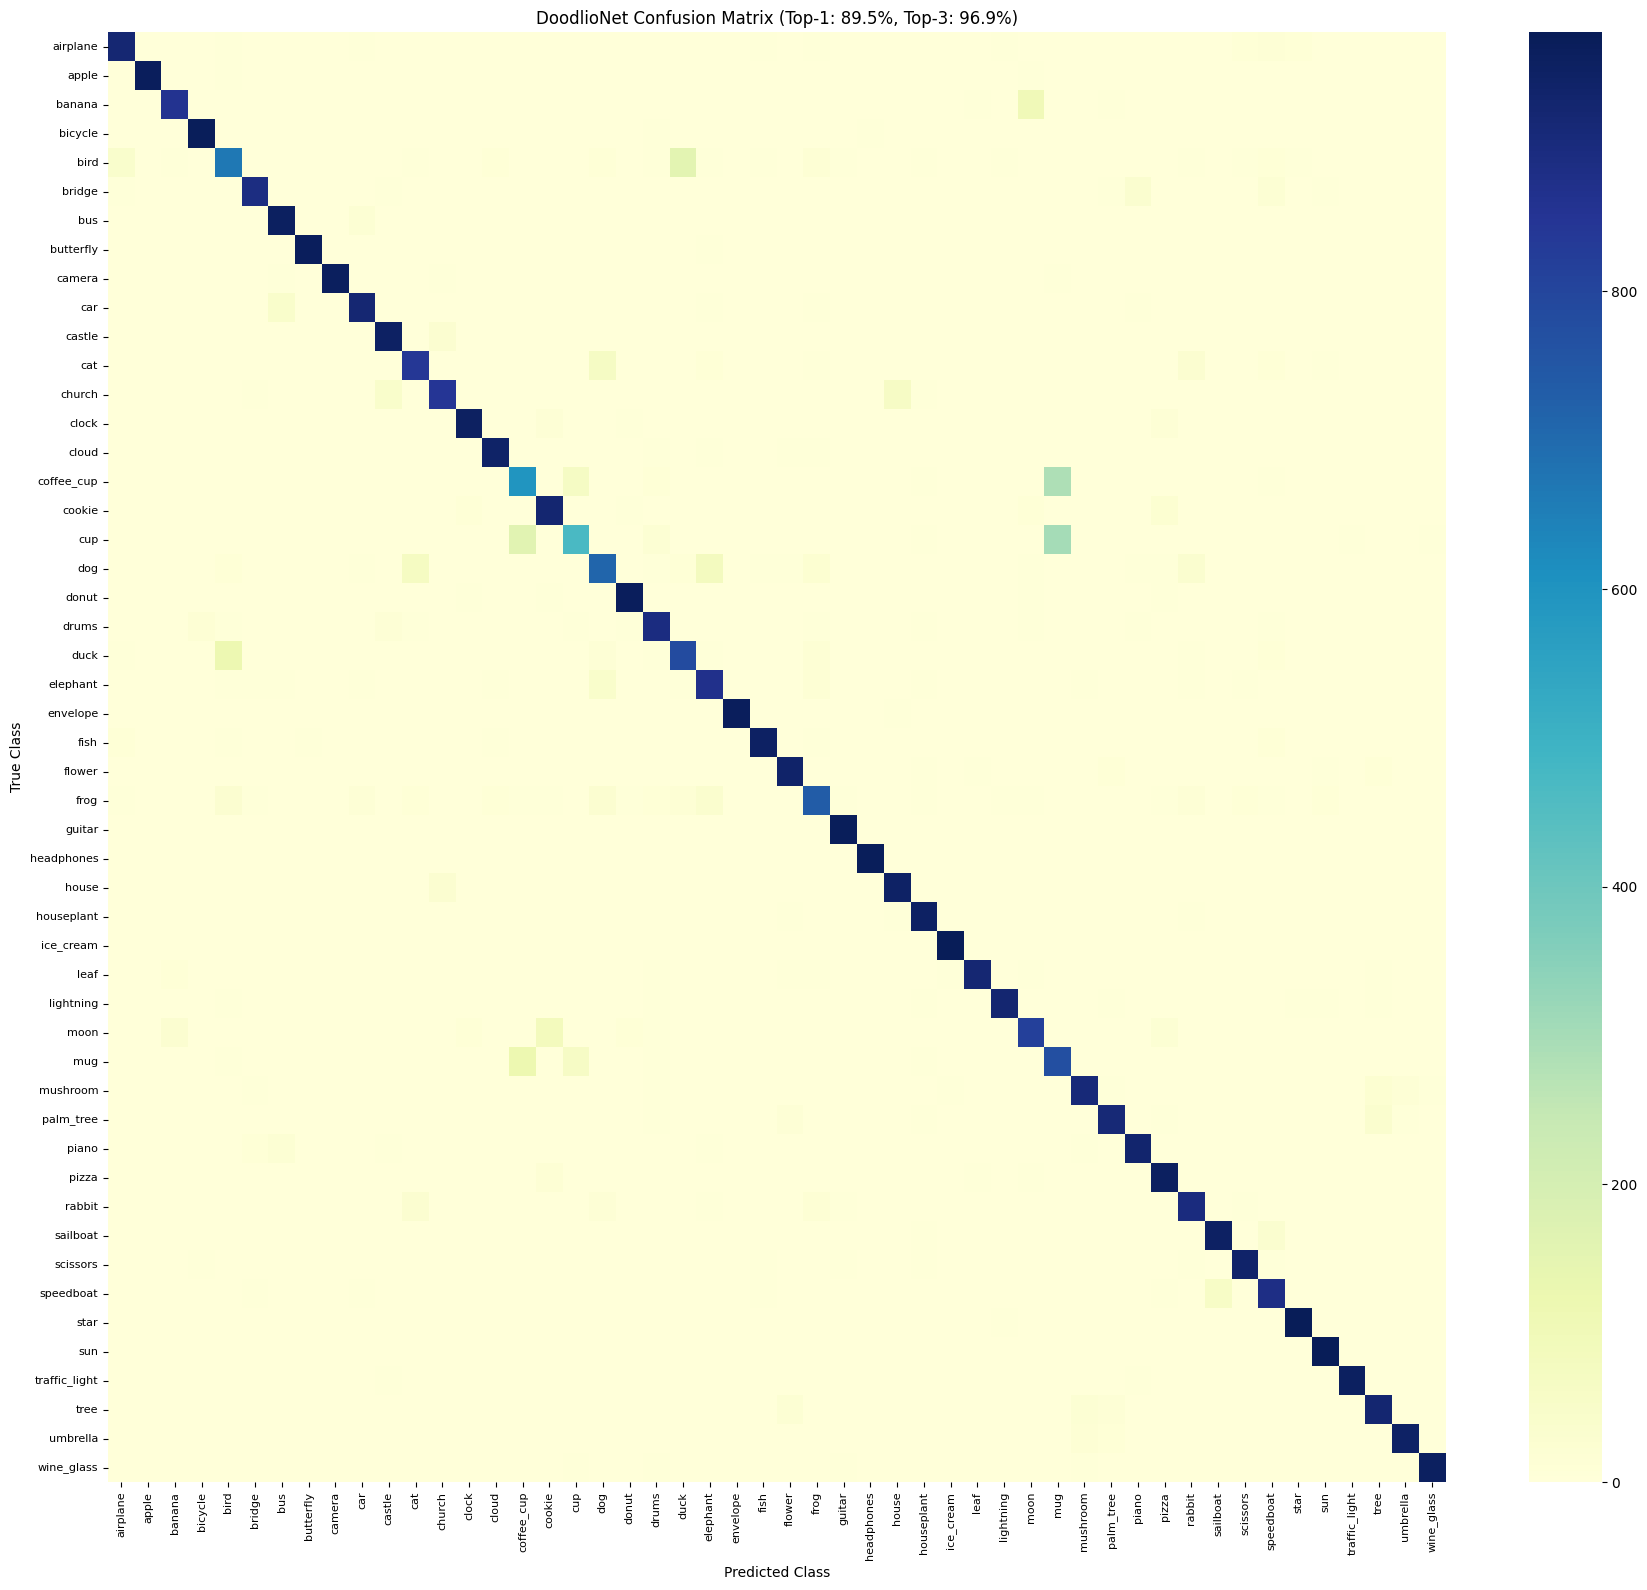

Evaluation artifacts saved to /content/artifacts/


In [20]:
import json
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load best checkpoint
model.load_state_dict(torch.load(CHECKPOINT_BEST, map_location=device))
model.eval()

all_preds = []
all_targets = []
top3_hits = 0

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Evaluating Test Set"):
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        _, top3 = logits.topk(3, dim=1)

        preds = logits.argmax(1).cpu().numpy()
        targets = labels.cpu().numpy()

        all_preds.extend(preds)
        all_targets.extend(targets)
        top3_hits += sum(labels[i] in top3[i] for i in range(labels.size(0)))

test_top1 = sum(p == t for p, t in zip(all_preds, all_targets)) / len(all_targets)
test_top3 = top3_hits / len(all_targets)

print("=" * 50)
print(f"FINAL TEST SET RESULTS (N = {len(all_targets):,}):")
print(f"  Top-1 Accuracy: {test_top1 * 100:.2f}%")
print(f"  Top-3 Accuracy: {test_top3 * 100:.2f}%")
print("=" * 50)

# Classification Report
target_names = [c["name"] for c in CATEGORIES]
report_dict = classification_report(all_targets, all_preds, target_names=target_names, output_dict=True)
report_dict["overall_top1_accuracy"] = float(test_top1)
report_dict["overall_top3_accuracy"] = float(test_top3)

with open("/content/artifacts/evaluation_report.json", "w") as f:
    json.dump(report_dict, f, indent=2)

# Confusion Matrix Plot
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(18, 16))
sns.heatmap(cm, xticklabels=target_names, yticklabels=target_names, cmap="YlGnBu", cbar=True)
plt.title(f"DoodlioNet Confusion Matrix (Top-1: {test_top1*100:.1f}%, Top-3: {test_top3*100:.1f}%)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig("/content/artifacts/confusion_matrix.png", dpi=200)
plt.show()
print("Evaluation artifacts saved to /content/artifacts/")



In [21]:
%pip install onnxscript onnx

## 10. ONNX Export & Artifact Packaging


In [22]:
import onnx
import onnxruntime as ort
import zipfile

# 1. Export to ONNX with dynamic batch size
model.eval()
dummy_input = torch.randn(1, 1, 28, 28, device=device)
onnx_path = "/content/artifacts/doodlio_model.onnx"

torch.onnx.export(
    model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=14,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={"input": {0: "batch_size"}, "logits": {0: "batch_size"}}
)

# 2. Verify ONNX Graph
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)
print("ONNX model validated successfully!")

# 3. Test ONNX Runtime inference
ort_session = ort.InferenceSession(onnx_path)
ort_inputs = {ort_session.get_inputs()[0].name: np.random.randn(1, 1, 28, 28).astype(np.float32)}
ort_outs = ort_session.run(None, ort_inputs)
print(f"ONNX Runtime inference test output shape: {ort_outs[0].shape}")

# 4. Generate Model Metadata JSON
metadata = {
    "model_name": "DoodlioNet",
    "version": "1.0.0",
    "format": "ONNX",
    "opset": 14,
    "input_shape": [1, 1, 28, 28],
    "input_dtype": "float32",
    "value_range": [0.0, 1.0],
    "num_classes": len(CATEGORIES),
    "classes": CATEGORIES,
    "metrics": {
        "test_top1_accuracy": float(test_top1),
        "test_top3_accuracy": float(test_top3)
    }
}

with open("/content/artifacts/model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

# 5. Package into doodlio_artifacts.zip
zip_path = "/content/doodlio_artifacts.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(onnx_path, "doodlio_model.onnx")
    zf.write("/content/artifacts/model_metadata.json", "model_metadata.json")
    zf.write("/content/artifacts/evaluation_report.json", "evaluation_report.json")
    zf.write("/content/artifacts/confusion_matrix.png", "confusion_matrix.png")

print(f"Artifacts successfully packaged into {zip_path}")
print("You can download this zip and extract it into your project's `models/` directory!")

from google.colab import files
files.download(zip_path)



/tmp/ipykernel_8008/2457965309.py:10: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1018 09:51:06.823000 8008 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 14 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `DoodlioNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DoodlioNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX model validated successfully!
ONNX Runtime inference test output shape: (1, 50)
Artifacts successfully packaged into /content/doodlio_artifacts.zip
You can download this zip and extract it into your project's `models/` directory!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import onnx
from google.colab import files

model_path = "/content/artifacts/doodlio_model.onnx"

model = onnx.load(model_path)
onnx.save_model(
    model,
    model_path,
    save_as_external_data=False
)

print("Model size:", round(
    __import__("os").path.getsize(model_path) / (1024 * 1024), 2
), "MB")

files.download(model_path)

Model size: 4.79 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>